# Taller 2 - Churn FinAlpes

Ciencia de Datos Aplicada (MINE-4101) - 2026-20

Integrantes: Sebastián Rodríguez y Louis Gualteros

## 0. Librerías y datos

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, RocCurveDisplay)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
df = pd.read_csv("churn.csv")
df.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


## 1. Entendimiento de los datos

Las secciones 1.1 y 1.2 describen los datos crudos, tal como vienen en churn.csv.

### 1.1 Dimensiones y tipos de variables


In [3]:
print("Registros y columnas:", df.shape)
df.info()

Registros y columnas: (10045, 11)
<class 'pandas.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  str    
 2   gender            10045 non-null  str    
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 863.4 KB


In [4]:
objetivo = "churn"
continuas = ["credit_score", "age", "balance", "estimated_salary"]
discretas = ["tenure", "products_number"]
categoricas = ["country", "gender"]
binarias = ["credit_card", "active_member"]

pd.DataFrame({
    "variable": continuas + discretas + categoricas + binarias + [objetivo],
    "tipo": (["Continua"] * len(continuas) + ["Discreta"] * len(discretas)
             + ["Categórica"] * len(categoricas) + ["Binaria"] * len(binarias) + ["Binaria (objetivo)"]),
}).set_index("variable").join(df.dtypes.rename("dtype_pandas"))

,tipo,dtype_pandas
variable,,
credit_score,Continua,float64
age,Continua,float64
balance,Continua,float64
estimated_salary,Continua,float64
tenure,Discreta,int64
products_number,Discreta,int64
country,Categórica,str
gender,Categórica,str
credit_card,Binaria,int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
credit_score,9795.0,650.690148,97.087963,95.0,584.000,652.00,718.000,1200.00
age,9745.0,38.937609,10.734222,-1.0,32.000,37.00,44.000,210.00
tenure,10045.0,5.018915,2.901585,-2.0,3.000,5.00,8.000,25.00
balance,9845.0,76317.500287,62422.434819,0.0,0.000,97042.60,127559.970,250898.09
products_number,10045.0,1.530114,0.581829,1.0,1.000,1.00,2.000,4.00
credit_card,10045.0,0.704530,0.456277,0.0,0.000,1.00,1.000,1.00
active_member,10045.0,0.514684,0.499809,0.0,0.000,1.00,1.000,1.00
estimated_salary,9695.0,100069.014751,57510.689111,-5000.0,51013.655,100130.95,149382.875,199992.48
churn,10045.0,0.203584,0.402683,0.0,0.000,0.00,0.000,1.00


El dataset tiene **10.045 registros y 11 columnas**: 10 variables que describen al cliente y la variable objetivo `churn` (1 = abandonó el banco).

- **Continuas:** credit_score, age, balance y estimated_salary.
- **Discretas:** tenure (años como cliente) y products_number (1 a 4).
- **Categóricas:** country y gender.
- **Binarias:** credit_card y active_member.

En el `describe` ya se ven cosas raras: edades de -1 y 210, credit_score de 95 y 1.200, tenure de -2 y 25 y salarios negativos.

### 1.2 Calidad de los datos

In [6]:
print("Registros duplicados:", df.duplicated().sum())

nulos = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": (df.isna().mean() * 100).round(2)})
nulos[nulos["nulos"] > 0]

Registros duplicados: 45


,nulos,porcentaje
credit_score,250,2.49
age,300,2.99
balance,200,1.99
estimated_salary,350,3.48


In [7]:
for columna in categoricas:
    print(df[columna].value_counts())
    print()

country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64

gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64



In [8]:
rangos = {
    "credit_score": (300, 850), "age": (18, 100), "tenure": (0, 10), "balance": (0, None),
    "products_number": (1, 4), "estimated_salary": (0, None),
}

def fuera_de_rango(datos, columna):
    minimo, maximo = rangos[columna]
    serie = datos[columna].dropna()
    debajo = (serie < minimo).sum() if minimo is not None else 0
    encima = (serie > maximo).sum() if maximo is not None else 0
    return int(debajo + encima)

for columna in rangos:
    minimo, maximo = rangos[columna]
    fuera = df[columna][(df[columna] < minimo) | ((df[columna] > maximo) if maximo is not None else False)]
    if len(fuera) > 0:
        print(f"{columna}: {len(fuera)} fuera de rango -> {sorted(fuera.unique().tolist())}")

credit_score: 4 fuera de rango -> [95.0, 120.0, 999.0, 1200.0]
age: 6 fuera de rango -> [-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]
tenure: 3 fuera de rango -> [-2, 15, 25]
estimated_salary: 3 fuera de rango -> [-5000.0, -120.5, -1.0]


- **Duplicados:** hay 45 filas repetidas.
- **Nulos:** están en 4 columnas y todos por debajo del 5 % (estimated_salary 3,5 %, age 3,0 %, credit_score 2,5 % y balance 2,0 %).
- **Consistencia:** country aparece escrito de 9 formas distintas (France, FRANCE, france...) y gender de 4 (Male/M, Female/F).
- **Validez:** credit_score tiene 4 valores fuera de 300-850, age 6 fuera de 18-100, tenure 3 fuera de 0-10 y estimated_salary 3 negativos.

### 1.3 Limpieza

Se eliminan los duplicados y se unifica la escritura de `country` y `gender`. Las edades, puntajes y antigüedades imposibles se dejan como nulos (recortarlos sería inventar un dato). Los salarios negativos (3 casos, hasta -5.000) se llevan a 0, porque un salario no puede ser negativo. Los nulos se imputan más adelante, después de dividir los datos, para no filtrar información del conjunto de prueba.

Rangos válidos: credit_score de 300 a 850 (escala FICO), edad de 18 a 100 y tenure de 0 a 10 (el máximo observado en los datos válidos).

In [9]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Se eliminaron {antes - len(df)} duplicados; quedan {len(df)} registros")

df["country"] = df["country"].str.strip().str.title()
df["gender"] = df["gender"].str.strip().replace({"M": "Male", "F": "Female"})

for columna in ["credit_score", "age", "tenure"]:
    minimo, maximo = rangos[columna]
    df.loc[(df[columna] < minimo) | (df[columna] > maximo), columna] = np.nan
df["estimated_salary"] = df["estimated_salary"].clip(lower=0)

print("Valores fuera de rango después de limpiar:", sum(fuera_de_rango(df, c) for c in rangos))
print(df["country"].value_counts().to_dict(), df["gender"].value_counts().to_dict())
df.isna().sum()[lambda s: s > 0]

Se eliminaron 45 duplicados; quedan 10000 registros
Valores fuera de rango después de limpiar: 0
{'France': 5014, 'Germany': 2509, 'Spain': 2477} {'Male': 5457, 'Female': 4543}


credit_score        254
age                 306
tenure                3
balance             200
estimated_salary    350
dtype: int64

### 1.4 Distribuciones

Desde aquí todo se calcula sobre los datos limpios: 10.000 clientes.

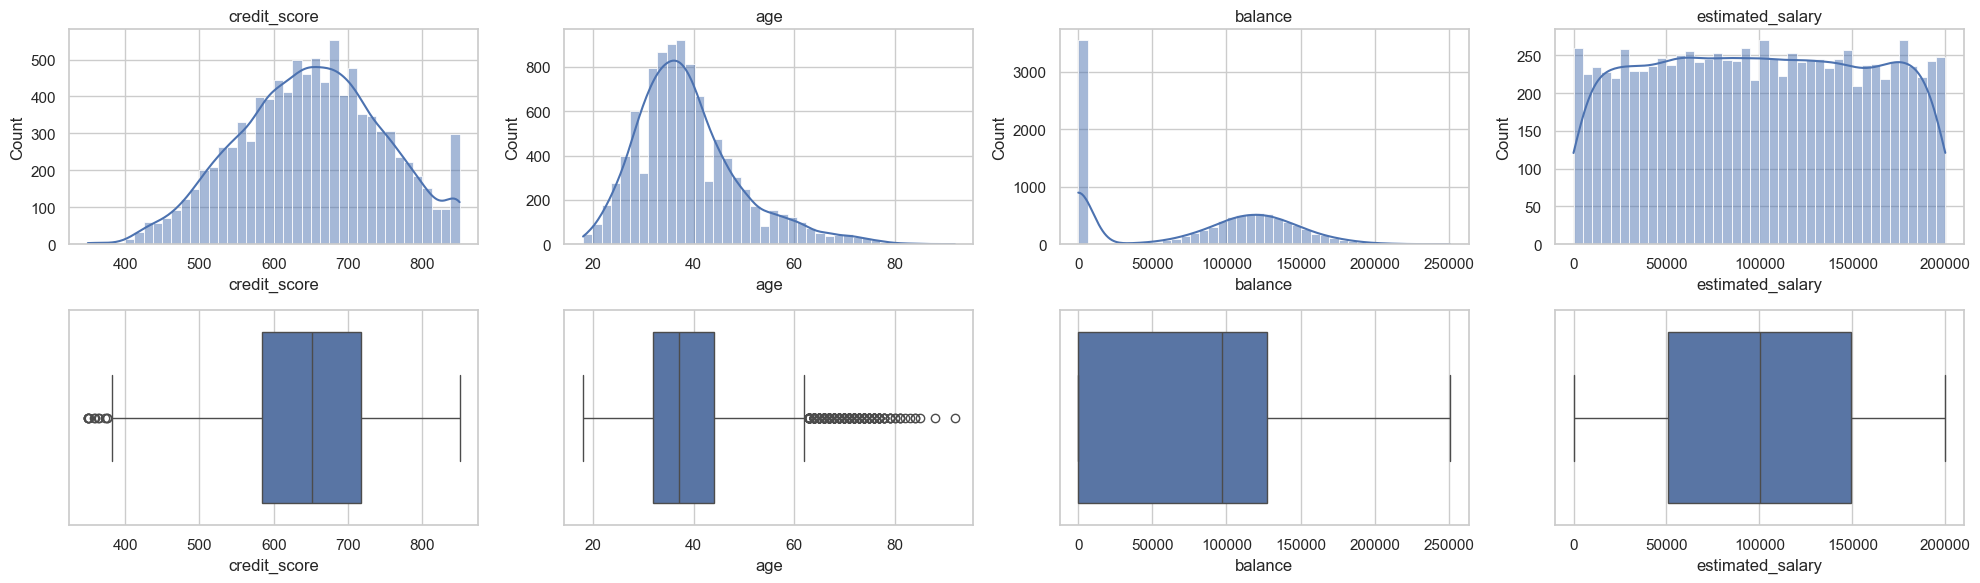

In [10]:
fig, axes = plt.subplots(2, len(continuas), figsize=(5 * len(continuas), 6))
for i, columna in enumerate(continuas):
    sns.histplot(df[columna], bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(columna)
    sns.boxplot(x=df[columna], ax=axes[1, i])
plt.tight_layout()
plt.show()

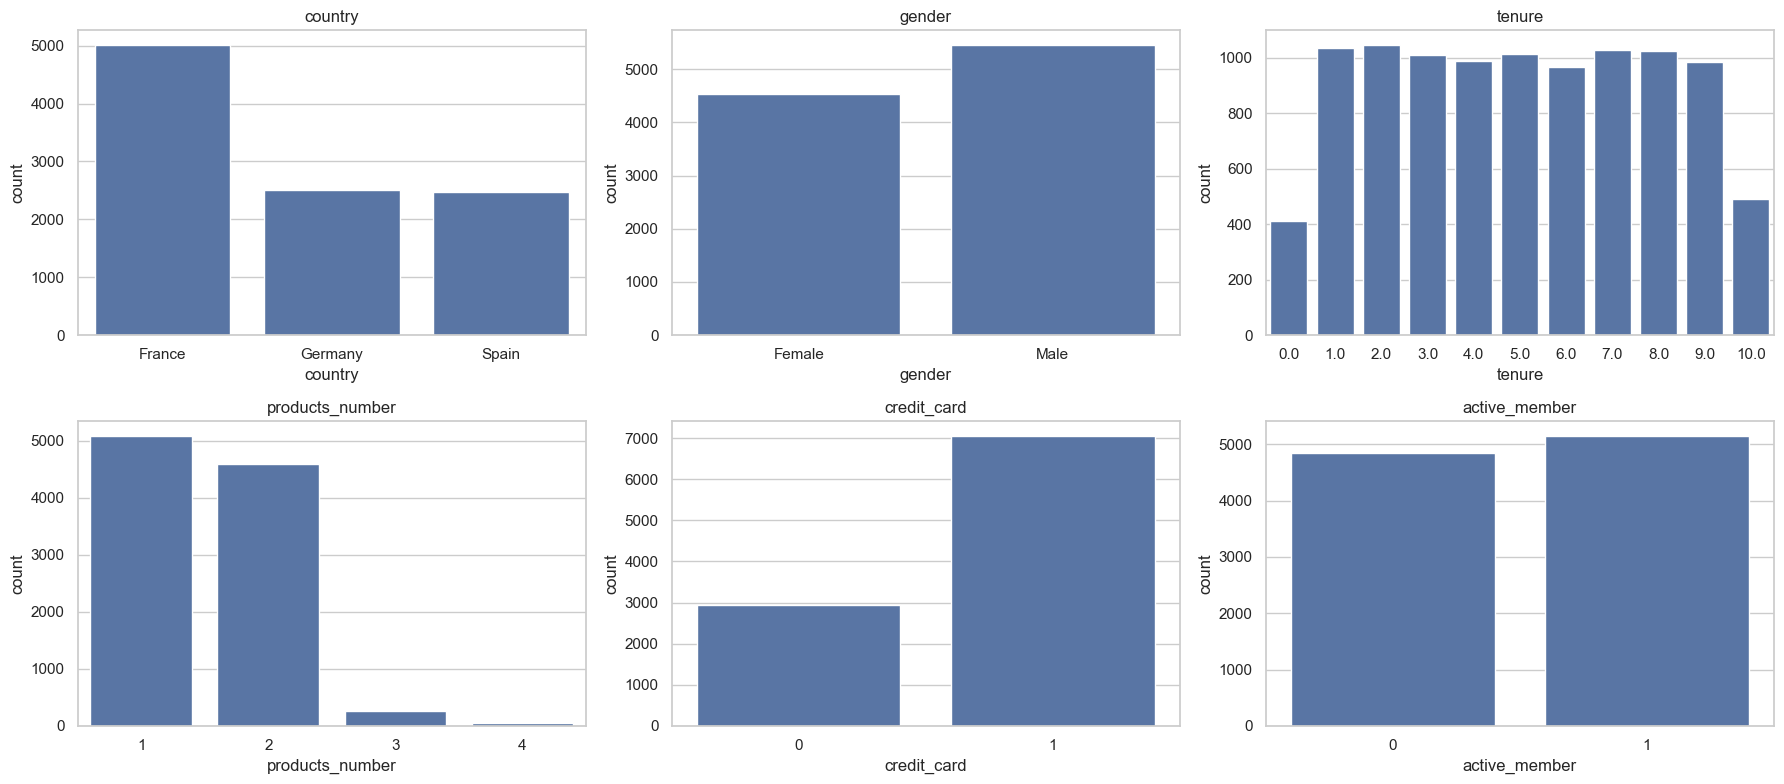

In [11]:
barras = categoricas + discretas + binarias
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, columna in zip(axes.flat, barras):
    sns.countplot(x=columna, data=df, ax=ax, order=sorted(df[columna].dropna().unique()))
    ax.set_title(columna)
plt.tight_layout()
plt.show()

In [12]:
# Indicadores citados en la lectura de distribuciones (datos limpios)
resumen = pd.DataFrame({
    "asimetria": df[continuas].skew(),
    "p25": df[continuas].quantile(0.25),
    "mediana": df[continuas].median(),
    "p75": df[continuas].quantile(0.75),
    "minimo": df[continuas].min(),
    "maximo": df[continuas].max(),
}).round(3)
print(resumen.to_string())
print()
print(f"Saldo 0 sobre todos los clientes: {(df['balance'] == 0).mean() * 100:.1f} %")
print(f"Saldo 0 sobre clientes con saldo informado: {(df['balance'].dropna() == 0).mean() * 100:.1f} %")
print(f"Mediana del saldo entre los que tienen saldo > 0: {df.loc[df['balance'] > 0, 'balance'].median():,.0f}")
print(f"Clientes con credit_score = 850: {(df['credit_score'] == 850).sum()}")
print(f"Valor más frecuente de credit_score: {df['credit_score'].mode()[0]:.0f}")
print(f"Salario mínimo y máximo: {df['estimated_salary'].min():,.0f} y {df['estimated_salary'].max():,.0f}")
tramos = pd.cut(df["estimated_salary"], [0, 50000, 100000, 150000, 200000], include_lowest=True)
print("% de clientes por tramo de salario (0-50k, 50-100k, 100-150k, 150-200k):",
      (tramos.value_counts(normalize=True, sort=False) * 100).round(1).tolist())
porcentajes = pd.concat({c: df[c].value_counts(normalize=True).mul(100).round(1)
                         for c in ["country", "products_number", "credit_card", "active_member"]})
print(porcentajes.to_string())
print(f"Tenure máximo en datos válidos: {int(df['tenure'].max())}")
print("Clientes por tenure:", df["tenure"].value_counts().sort_index().astype(int).to_dict())


                  asimetria        p25    mediana         p75  minimo     maximo
credit_score         -0.068    584.000     652.00     718.000   350.0     850.00
age                   0.996     32.000      37.00      44.000    18.0      92.00
balance              -0.137      0.000   97038.69  127537.155     0.0  250898.09
estimated_salary      0.004  51012.472  100129.33  149370.550     0.0  199992.48

Saldo 0 sobre todos los clientes: 35.6 %
Saldo 0 sobre clientes con saldo informado: 36.3 %
Mediana del saldo entre los que tienen saldo > 0: 119,826
Clientes con credit_score = 850: 227
Valor más frecuente de credit_score: 850
Salario mínimo y máximo: 0 y 199,992
% de clientes por tramo de salario (0-50k, 50-100k, 100-150k, 150-200k): [24.6, 25.4, 25.5, 24.5]
country          France     50.1
                 Germany    25.1
                 Spain      24.8
products_number  1          50.8
                 2          45.9
                 3           2.7
                 4           0.6


In [13]:
# Efecto de la limpieza: datos crudos (solo para comparar) frente a limpios; df no se modifica
crudo = pd.read_csv("churn.csv")
comparacion = pd.DataFrame({
    "crudo": {"registros": len(crudo), "nulos_totales": int(crudo.isna().sum().sum()),
              "asimetria_age": crudo["age"].skew(), "corr_age_churn": crudo["age"].corr(crudo["churn"])},
    "limpio": {"registros": len(df), "nulos_totales": int(df.isna().sum().sum()),
               "asimetria_age": df["age"].skew(), "corr_age_churn": df["age"].corr(df["churn"])},
}).round(3)
print(comparacion.to_string())

                    crudo     limpio
registros       10045.000  10000.000
nulos_totales    1100.000   1113.000
asimetria_age       1.494      0.996
corr_age_churn      0.274      0.283


- **age** tiene sesgo a la derecha (asimetría 0,996): las edades van de 18 a 92 años y el 50 % central de los clientes tiene entre 32 y 44 años.
- **balance** es bimodal: el 35,6 % de los 10.000 clientes tiene saldo 0 (36,3 % si solo se cuentan los que tienen saldo informado). Entre los que tienen saldo, la mediana es 119.826, cerca de 120 mil.
- **credit_score** es casi simétrico (asimetría -0,068), con un pico en 850, el máximo de la escala: 227 clientes lo tienen, y es el valor más frecuente.
- **estimated_salary** es prácticamente uniforme entre 0 y 200 mil: cada tramo de 50 mil reúne entre 24,5 % y 25,5 % de los clientes.
- En las categóricas, Francia tiene el 50,1 % de los clientes y Alemania y España 25,1 % y 24,8 %. Casi todos tienen 1 o 2 productos: 3 y 4 productos son muy raros (2,7 % y 0,6 %). El 70,6 % tiene tarjeta de crédito y el 51,5 % es miembro activo. Por género hay 5.457 hombres y 4.543 mujeres, y la antigüedad (tenure) se reparte de forma pareja: 413 clientes con 0 años, 490 con 10 y entre 967 y 1.046 en cada año de 1 a 9.

### 1.5 Variable objetivo

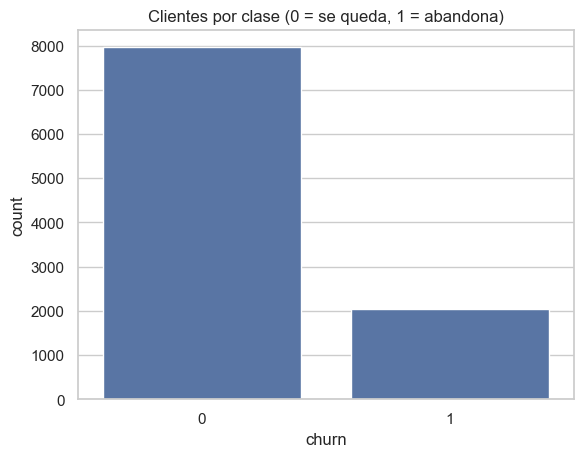

churn
0    7963
1    2037
Name: count, dtype: int64
churn
0    0.7963
1    0.2037
Name: proportion, dtype: float64
Tasa de churn: 20.4 % (referencia del enunciado: 15 %)
Clientes que se quedan por cada uno que se va: 3.9
Exactitud de un modelo que siempre predice 0: 79.6 %


In [12]:
sns.countplot(x=objetivo, data=df)
plt.title("Clientes por clase (0 = se queda, 1 = abandona)")
plt.show()

print(df[objetivo].value_counts())
print(df[objetivo].value_counts(normalize=True).round(4))

referencia = 0.15  # tasa de referencia del enunciado
print(f"Tasa de churn: {df[objetivo].mean() * 100:.1f} % (referencia del enunciado: {referencia * 100:.0f} %)")
print(f"Clientes que se quedan por cada uno que se va: {(df[objetivo] == 0).sum() / (df[objetivo] == 1).sum():.1f}")
print(f"Exactitud de un modelo que siempre predice 0: {(df[objetivo] == 0).mean() * 100:.1f} %")

El **20,4 % de los clientes abandonó** (2.037 de 10.000). Las clases están desbalanceadas: hay 3,9 clientes que se quedan por cada uno que se va. Por eso la exactitud no sirve para evaluar: un modelo que diga siempre "no abandona" acierta el 79,6 % de los casos. Hay que mirar recall, precisión, F1 y AUC, y estratificar al dividir los datos.

La tasa del dataset (20,4 %) está por encima del 15 % de referencia del enunciado. Esto hay que tenerlo en cuenta al proyectar los resultados a la base completa de clientes.

### 1.6 Churn según cada variable

Tasa de abandono por grupo y comparación de las variables continuas entre los que se quedan y los que se van.

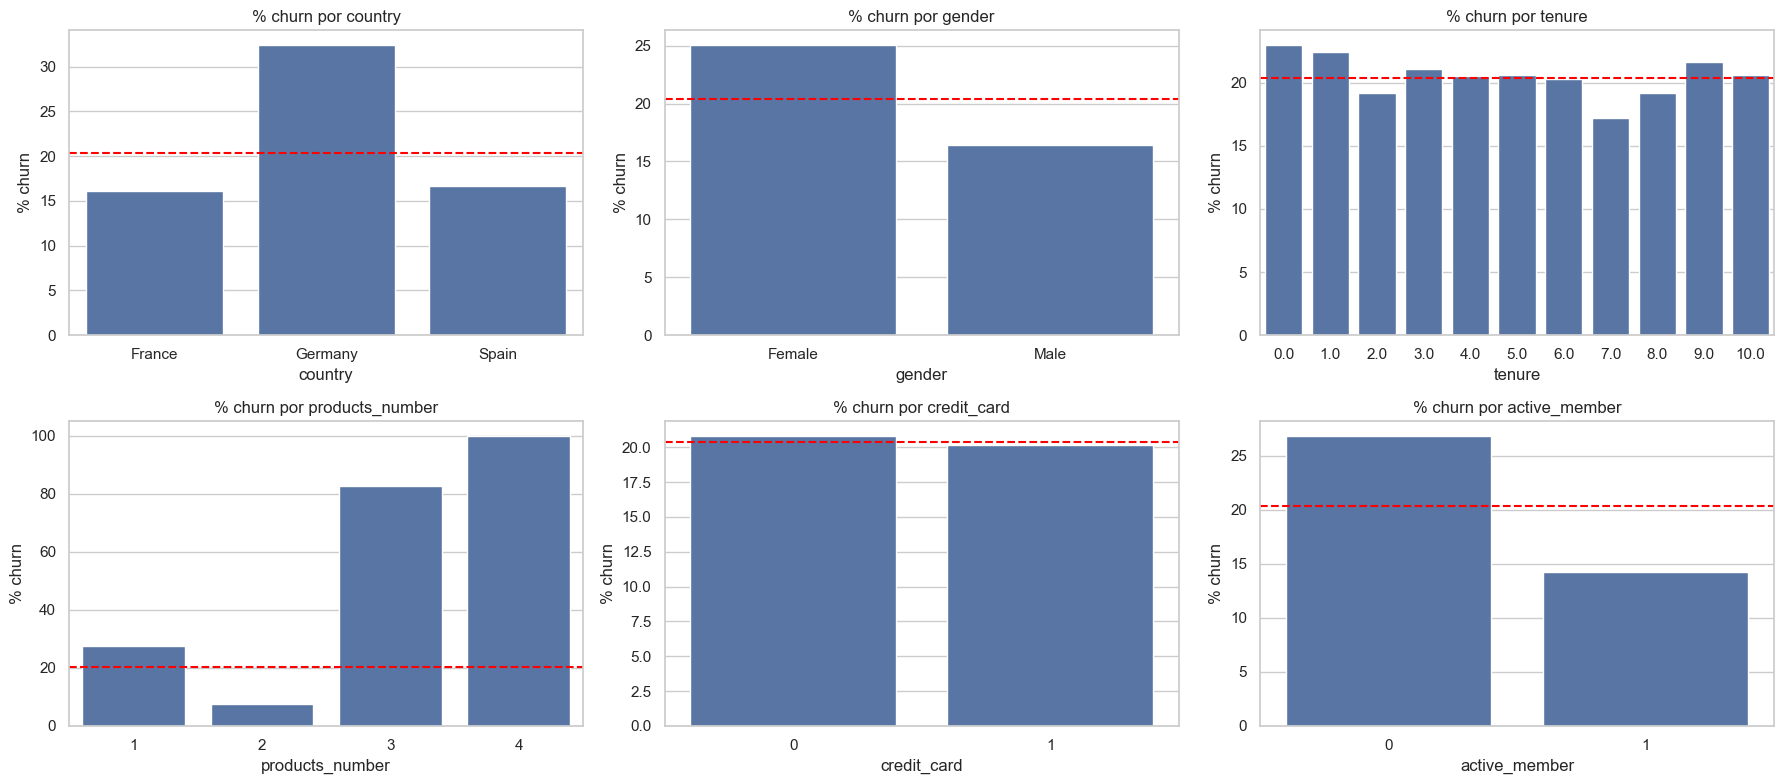

In [13]:
tasa_global = df[objetivo].mean()
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, columna in zip(axes.flat, barras):
    tasa = df.groupby(columna)[objetivo].mean().mul(100)
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax)
    ax.axhline(tasa_global * 100, color="red", linestyle="--")
    ax.set_title(f"% churn por {columna}")
    ax.set_ylabel("% churn")
plt.tight_layout()
plt.show()

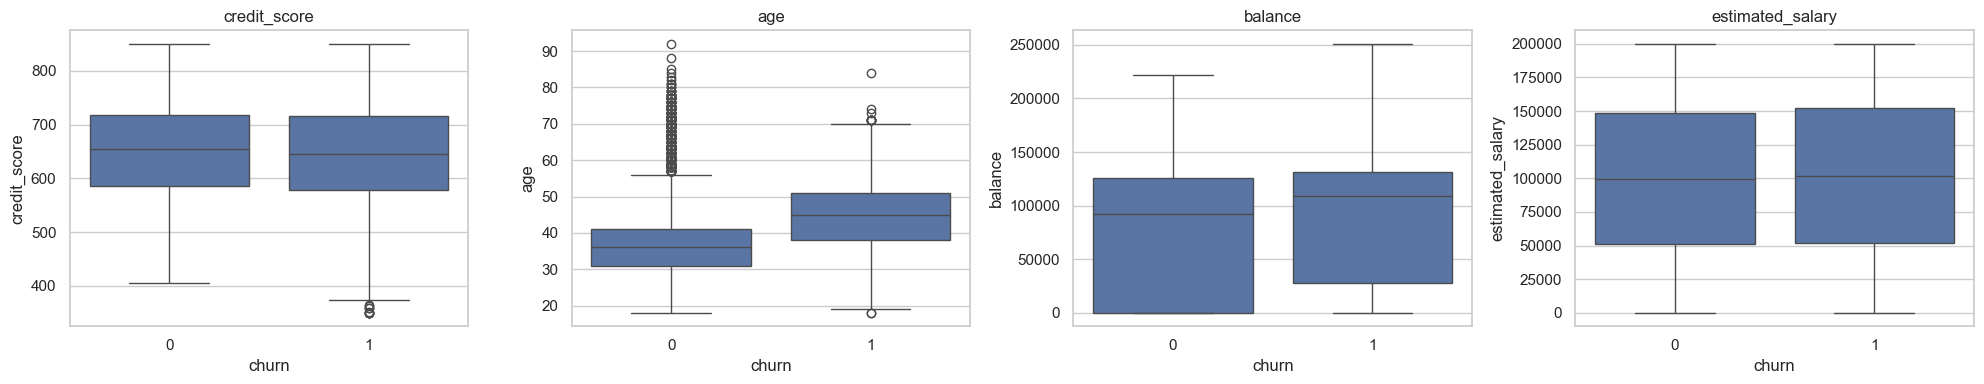

,credit_score,age,balance,estimated_salary
churn,,,,
0,654.0,36.0,91835.2,99645.0
1,646.0,45.0,109154.0,101954.8


In [14]:
fig, axes = plt.subplots(1, len(continuas), figsize=(5 * len(continuas), 4))
for ax, columna in zip(axes, continuas):
    sns.boxplot(x=objetivo, y=columna, data=df, ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

df.groupby(objetivo)[continuas].median().round(1)

In [15]:
df["grupo_edad"] = pd.cut(df["age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
tasa_edad = df.groupby("grupo_edad", observed=True)[objetivo].agg(churn_pct="mean", n="count")
tasa_edad["churn_pct"] = (tasa_edad["churn_pct"] * 100).round(1)
print(tasa_edad.to_string())
df = df.drop(columns="grupo_edad")

            churn_pct     n
grupo_edad                 
18-30             7.7  1910
31-40            12.3  4304
41-50            33.8  2252
51-60            56.0   782
60+              24.7   446


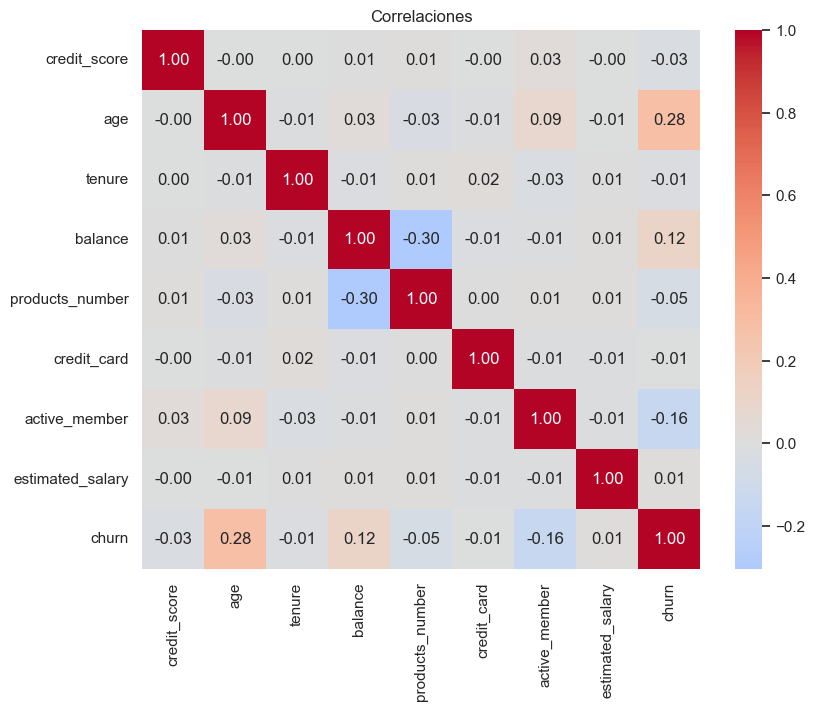

In [16]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones")
plt.show()

In [19]:
# Tasa de churn (%) y n por grupo; saldo 0 frente a saldo > 0 (los nulos de balance quedan como "sin dato")
df_grupos = df.assign(saldo=np.select([df["balance"] > 0, df["balance"] == 0],
                                      ["saldo > 0", "saldo 0"], default="sin dato"))
filas = []
for variable in ["country", "gender", "products_number", "active_member", "credit_card", "tenure", "saldo"]:
    for grupo, churn_grupo in df_grupos.groupby(variable)[objetivo]:
        filas.append({"variable": variable, "grupo": grupo,
                      "churn_%": round(churn_grupo.mean() * 100, 1), "n": len(churn_grupo)})
print(pd.DataFrame(filas).to_string(index=False))
print()

# Correlación de cada variable numérica con churn
correlacion = df.select_dtypes("number").corr(numeric_only=True)[objetivo].drop(objetivo)
print(correlacion.reindex(correlacion.abs().sort_values(ascending=False).index).round(3).to_string())

       variable     grupo  churn_%    n
        country    France     16.2 5014
        country   Germany     32.4 2509
        country     Spain     16.7 2477
         gender    Female     25.1 4543
         gender      Male     16.5 5457
products_number         1     27.7 5084
products_number         2      7.6 4590
products_number         3     82.7  266
products_number         4    100.0   60
  active_member         0     26.9 4849
  active_member         1     14.3 5151
    credit_card         0     20.8 2945
    credit_card         1     20.2 7055
         tenure       0.0     23.0  413
         tenure       1.0     22.4 1034
         tenure       2.0     19.2 1046
         tenure       3.0     21.1 1009
         tenure       4.0     20.5  989
         tenure       5.0     20.7 1012
         tenure       6.0     20.3  967
         tenure       7.0     17.2 1028
         tenure       8.0     19.2 1025
         tenure       9.0     21.6  984
         tenure      10.0     20.6  490


In [20]:
# Porcentaje de saldo 0 por país (sobre clientes con saldo informado)
saldo_pais = df.dropna(subset=["balance"]).groupby("country")["balance"].agg(
    n="count", saldo_0_pct=lambda s: round((s == 0).mean() * 100, 1))
print(saldo_pais.to_string())

            n  saldo_0_pct
country                   
France   4911         48.4
Germany  2456          0.0
Spain    2433         48.7


Las variables que más se asocian con el abandono son:

- **Edad:** es la de mayor correlación lineal con churn (0,283, en el mapa de calor y en la tabla de correlaciones). La tasa sube de 7,7 % en el grupo de 18 a 30 años a 33,8 % entre 41 y 50 y a 56,0 % entre 51 y 60; en el grupo de 60+ baja a 24,7 %. La mediana de edad de los que abandonan es 45 años, contra 36 de los que se quedan.
- **Número de productos:** la tasa es de 27,7 % con 1 producto y de 7,6 % con 2. Con 3 productos es de 82,7 % (n = 266) y con 4 de 100,0 % (n = 60); son grupos pequeños.
- **País:** Alemania presenta mayor tasa, 32,4 %, frente a 16,2 % en Francia y 16,7 % en España. Ver la advertencia sobre el saldo más abajo.
- **Miembro activo:** los inactivos presentan 26,9 % de churn, contra 14,3 % de los activos.
- **Género:** las mujeres presentan 25,1 % de churn, contra 16,5 % de los hombres.
- **Saldo:** los clientes con saldo > 0 presentan 24,1 % de churn, contra 13,9 % de los que tienen saldo 0.

**Advertencia sobre país y saldo:** están entrelazados. Ningún cliente de Alemania tiene saldo 0 (0,0 %), mientras que en Francia lo tienen el 48,4 % y en España el 48,7 % (tabla de saldo por país, arriba). Por eso la asociación de Alemania y la del saldo no deben leerse por separado: el modelo los verá juntos.

Las variables con **poca asociación lineal o por grupos** son credit_score, estimated_salary, tenure y credit_card. Su correlación con churn no supera 0,028 en valor absoluto (credit_score: -0,028). La tasa por antigüedad va de 17,2 % a 23,0 % sin tendencia clara, y la de tarjeta de crédito es 20,8 % sin tarjeta y 20,2 % con tarjeta. En los diagramas de caja, las medianas de los que se van frente a los que se quedan son casi iguales en credit_score (646 contra 654) y en estimated_salary (101.955 contra 99.645), y algo mayor en balance (109.154 contra 91.835).

### Conclusiones de la sección 1

Después de la limpieza quedan **10.000 clientes**. No hay duplicados, las categorías están unificadas y los valores imposibles de edad, puntaje y antigüedad se convirtieron en nulos (los salarios negativos se llevaron a 0). Quedan nulos en credit_score, age, tenure, balance y estimated_salary, que se imputan en la sección 2 con la mediana del conjunto de entrenamiento.

Los perfiles con mayor tasa de churn son los de 41 a 60 años, los de Alemania, los inactivos y los que tienen saldo. Las relaciones no son lineales: la tasa sube hasta 56,0 % entre 51 y 60 años y luego baja a 24,7 % en 60+; con productos, baja a 7,6 % con 2 y sube a 82,7 % con 3. Por eso conviene probar modelos de árboles, además de uno lineal como referencia.

**Variables con pocos datos.** products_number = 4 tiene 100,0 % de churn, pero solo n = 60 clientes; products_number = 3 tiene 82,7 % con n = 266. Se mantienen porque son datos observados, pero su efecto se interpreta con cautela. El dataset tampoco indica cuándo se mide active_member: se supone que es antes del abandono, y conviene confirmarlo con el banco.

Ninguna variable parece medida después del abandono y no hay identificadores, así que no se descarta ninguna por fuga de información.

## 2. Modelos

Se prueban tres modelos:
- **Regresión logística**, como línea base.
- **Random Forest**.
- **Gradient Boosting**.

En la sección 1 vimos que la edad y el número de productos no tienen una relación lineal con el churn, así que se espera que los modelos de árboles funcionen mejor.

### 2.1 Preparación y división de los datos

Se usan todas las variables. country y gender se pasan a dummies. Los datos se dividen en 60 % entrenamiento, 20 % validación y 20 % prueba, de forma estratificada y con `random_state=42`. Los nulos se imputan con la mediana del entrenamiento y después se escala. El conjunto de prueba no se usa en esta sección.

**Por qué se mantienen todas las variables.** Todas son atributos del cliente y de su cuenta que se supone que se conocen antes de que decida irse (el dataset no documenta cuándo se midió cada una), así que no se espera fuga de información. `products_number` = 4 tiene 100 % de churn, pero en solo 60 clientes (con 3 productos es 82,7 %, en 266); se mantiene porque se mide antes del churn y no es la etiqueta. Las variables con menor asociación individual (AUC univariado entre 0,505 y 0,518 en credit_card, estimated_salary, tenure y credit_score) también se mantienen: solas casi no separan, pero un árbol puede usarlas en interacciones. El punto 4 revisa su aporte con importancia por permutación.

El escalado solo lo necesita la regresión logística; no afecta a los árboles, que no cambian con transformaciones monótonas de cada columna. Las medianas y el escalador se calculan con todo el entrenamiento antes de la validación cruzada, así que los folds de validación comparten esos estadísticos (fuga mínima, aceptada por simplicidad). Los nulos imputados en el entrenamiento (6.000 clientes) son 186 en age, 196 en estimated_salary, 146 en credit_score, 120 en balance y 2 en tenure.


In [17]:
datos = pd.get_dummies(df, columns=categoricas, drop_first=True, dtype=int)
columnas = datos.columns.drop(objetivo).tolist()
X = datos[columnas]
y = datos[objetivo]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

medianas = X_train.median()
X_train, X_val, X_test = X_train.fillna(medianas), X_val.fillna(medianas), X_test.fillna(medianas)

escalador = StandardScaler()
X_train_esc = pd.DataFrame(escalador.fit_transform(X_train), columns=columnas, index=X_train.index)
X_val_esc = pd.DataFrame(escalador.transform(X_val), columns=columnas, index=X_val.index)
X_test_esc = pd.DataFrame(escalador.transform(X_test), columns=columnas, index=X_test.index)

print("Columnas:", columnas)
pd.DataFrame({
    "registros": [len(s) for s in (y_train, y_val, y_test)],
    "proporcion_churn": [round(float(s.mean()), 4) for s in (y_train, y_val, y_test)],
}, index=["Entrenamiento", "Validación", "Prueba"])

Columnas: ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'country_Germany', 'country_Spain', 'gender_Male']


,registros,proporcion_churn
Entrenamiento,6000,0.2038
Validación,2000,0.2035
Prueba,2000,0.2035


In [22]:
# Evidencia para mantener todas las variables: asociación individual con el churn (en entrenamiento) y nulos imputados
asociacion = pd.DataFrame({
    "AUC univariado": [max(roc_auc_score(y_train, X_train[c]), 1 - roc_auc_score(y_train, X_train[c])) for c in columnas],
    "nulos imputados": [int(df.loc[X_train.index, c].isna().sum()) if c in df.columns else 0 for c in columnas],
}, index=columnas).sort_values("AUC univariado", ascending=False)
print(asociacion.round(3))

por_productos = df.groupby("products_number")[objetivo].agg(clientes="size", churn="mean")
print(por_productos.round(3))

                  AUC univariado  nulos imputados
age                        0.728              186
active_member              0.599                0
country_Germany            0.588                0
products_number            0.578                0
balance                    0.573              120
gender_Male                0.565                0
country_Spain              0.524                0
credit_score               0.518              146
tenure                     0.510                2
estimated_salary           0.506              196
credit_card                0.505                0
                 clientes  churn
products_number                 
1                    5084  0.277
2                    4590  0.076
3                     266  0.827
4                      60  1.000


### 2.2 Búsqueda de hiperparámetros

Se usa `GridSearchCV` con validación cruzada estratificada de 5 folds sobre el entrenamiento, con los mismos folds para todos los modelos. Cada modelo se reajusta con la combinación de mayor **AUC** (`refit="roc_auc"`), y se reporta también el **AP** (precisión promedio) como métrica de apoyo, siempre como media ± desviación estándar entre folds.

Se usa AUC y no F1 porque la campaña contacta a los clientes en orden de riesgo y el umbral (a cuántos contactar) se fija después, según costo y beneficio, en la sección 5. Lo que importa es que el modelo ordene bien. El AP pesa más el tope del ranking, que es donde se gasta el presupuesto.


In [23]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tiempos = {}
resumen_cv = {}

def buscar(nombre, modelo, rejilla):
    inicio = time.time()
    busqueda = GridSearchCV(modelo, rejilla, cv=skf, scoring={"roc_auc": "roc_auc", "ap": "average_precision"},
                            refit="roc_auc", n_jobs=-1)
    busqueda.fit(X_train_esc, y_train)
    tiempos[nombre] = time.time() - inicio
    r, i = busqueda.cv_results_, busqueda.best_index_
    resumen_cv[nombre] = {"AUC CV": r["mean_test_roc_auc"][i], "AUC CV std": r["std_test_roc_auc"][i],
                          "AP CV": r["mean_test_ap"][i], "AP CV std": r["std_test_ap"][i]}
    print("Mejor combinación:", busqueda.best_params_)
    print(f"AUC de validación cruzada: {r['mean_test_roc_auc'][i]:.3f} ± {r['std_test_roc_auc'][i]:.3f} (desviación entre folds)")
    print(f"AP de validación cruzada: {r['mean_test_ap'][i]:.3f} ± {r['std_test_ap'][i]:.3f}")
    print(f"tiempo: {tiempos[nombre]:.0f} s")
    return busqueda


In [19]:
busqueda_logistica = buscar("Regresión logística", LogisticRegression(max_iter=1000),
                            {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]})

Mejor combinación: {'C': 0.1, 'class_weight': 'balanced'}
AUC de validación cruzada: 0.761 ± 0.027 (desviación entre folds)
AP de validación cruzada: 0.457 ± 0.029
tiempo: 0 s


In [20]:
busqueda_rf = buscar("Random Forest", RandomForestClassifier(random_state=42),
                     {"n_estimators": [200, 400], "max_depth": [5, 10, None], "min_samples_leaf": [1, 5, 20],
                      "class_weight": [None, "balanced"]})
pd.DataFrame(busqueda_rf.cv_results_).sort_values("mean_test_roc_auc", ascending=False)[
    ["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_class_weight", "mean_test_roc_auc"]
].head(5).round(3)

Mejor combinación: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
AUC de validación cruzada: 0.865 ± 0.010 (desviación entre folds)
AP de validación cruzada: 0.685 ± 0.027
tiempo: 96 s


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_roc_auc
24,200,10,1,balanced,0.865
25,400,10,1,balanced,0.865
26,200,10,5,balanced,0.864
7,400,10,1,None,0.864
27,400,10,5,balanced,0.864


In [21]:
busqueda_gb = buscar("Gradient Boosting", GradientBoostingClassifier(random_state=42),
                     {"n_estimators": [100, 200, 300], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3, 4]})
pd.DataFrame(busqueda_gb.cv_results_).pivot_table(index=["param_max_depth", "param_n_estimators"],
                                                  columns="param_learning_rate", values="mean_test_roc_auc").round(3)

Mejor combinación: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
AUC de validación cruzada: 0.868 ± 0.007 (desviación entre folds)
AP de validación cruzada: 0.707 ± 0.017
tiempo: 80 s


param_learning_rate                  0.02   0.05   0.10
param_max_depth param_n_estimators                     
2               100                 0.838  0.856  0.861
                200                 0.852  0.862  0.862
                300                 0.859  0.863  0.862
3               100                 0.849  0.865  0.867
                200                 0.862  0.868  0.864
                300                 0.866  0.866  0.862
4               100                 0.857  0.865  0.865
                200                 0.864  0.866  0.860
                300                 0.865  0.864  0.856

Mejores combinaciones (AUC de validación cruzada, media ± desviación entre folds; entre paréntesis el AP de validación cruzada):

- **Regresión logística:** C = 0,1 con `class_weight="balanced"` (0,761 ± 0,027; AP 0,457).
- **Random Forest:** 200 árboles, `max_depth=10`, `min_samples_leaf=1` y `class_weight="balanced"` (0,865 ± 0,010; AP 0,685). Las primeras cinco combinaciones quedan entre 0,864 y 0,865 y todas tienen `max_depth=10`, así que entre las mejores combinaciones las diferencias son de 0,001, mucho menores que la desviación entre folds.
- **Gradient Boosting:** 200 árboles, `learning_rate=0,05` y `max_depth=3` (0,868 ± 0,007; AP 0,707). La rejilla cubre de 100 a 300 árboles, tasa de 0,02 a 0,1 y profundidad de 2 a 4, y el óptimo queda en el interior, no en un borde. Sus vecinos inmediatos no mejoran: 0,867 con 100 árboles y tasa 0,1, 0,866 con 300 árboles y tasa 0,05, y 0,862 con 200 árboles y tasa 0,02. No se probó `subsample`, para mantener corta la búsqueda.

Los dos modelos de árboles le sacan unos 10 puntos de AUC a la regresión logística (0,865 y 0,868 contra 0,761), como se esperaba.


In [27]:
# ¿Cambia algo si el Gradient Boosting se entrena con pesos balanceados? Mismos hiperparámetros, mismos folds
from sklearn.model_selection import cross_validate
from sklearn.utils.class_weight import compute_sample_weight

pesos = compute_sample_weight("balanced", y_train)
mejor_gb = GradientBoostingClassifier(random_state=42, **busqueda_gb.best_params_)
filas_w = {}
for etiqueta, parametros in [("sin pesos", None), ("con pesos balanceados", {"sample_weight": pesos})]:
    cv = cross_validate(mejor_gb, X_train_esc, y_train, cv=skf, scoring={"roc_auc": "roc_auc", "ap": "average_precision"},
                        params=parametros)
    modelo_w = GradientBoostingClassifier(random_state=42, **busqueda_gb.best_params_)
    modelo_w.fit(X_train_esc, y_train, sample_weight=None if parametros is None else pesos)
    prob = modelo_w.predict_proba(X_val_esc)[:, 1]
    pred = (prob >= 0.5).astype(int)
    filas_w[etiqueta] = {"AUC CV": cv["test_roc_auc"].mean(), "AUC CV std": cv["test_roc_auc"].std(),
                         "AP CV": cv["test_ap"].mean(), "AP CV std": cv["test_ap"].std(),
                         "AUC val": roc_auc_score(y_val, prob), "AP val": average_precision_score(y_val, prob),
                         "prob. media val": prob.mean(), "precisión val (0,5)": precision_score(y_val, pred),
                         "recall val (0,5)": recall_score(y_val, pred)}
print("Proporción real de churn en validación:", round(float(y_val.mean()), 4))
comparacion_pesos = pd.DataFrame(filas_w).T
comparacion_pesos.round(3)

Proporción real de churn en validación: 0.2035


,AUC CV,AUC CV std,AP CV,AP CV std,AUC val,AP val,prob. media val,"precisión val (0,5)","recall val (0,5)"
sin pesos,0.868,0.007,0.707,0.017,0.848,0.677,0.196,0.770,0.459
con pesos balanceados,0.865,0.008,0.702,0.019,0.845,0.667,0.364,0.494,0.715


**Pesos balanceados en el Gradient Boosting.** Con los mismos hiperparámetros y folds, entrenar con `sample_weight` balanceado da un AUC de CV de 0,865 ± 0,008 contra 0,868 ± 0,007 sin pesos, y un AP de CV de 0,702 contra 0,707. La diferencia es menor que la desviación entre folds: los pesos casi no cambian el ordenamiento (el AUC de validación pasa de 0,848 a 0,845). Lo que cambia es la probabilidad. La media de las probabilidades en validación pasa de 0,196 (la proporción real de churn es 0,2035) a 0,364, y con umbral 0,5 el recall sube de 0,459 a 0,715 mientras la precisión baja de 0,770 a 0,494. Es decir, sin pesos el modelo es más conservador a umbral 0,5 pero su probabilidad media se acerca a la tasa real; los pesos se asocian sobre todo con un cambio del punto de corte efectivo. Como el umbral se decide en la sección 5, se deja el Gradient Boosting sin pesos.


### 2.3 Selección del modelo

Se comparan los tres modelos con el AUC de CV (± desviación entre folds) y con entrenamiento y validación. Precisión, recall y F1 de validación usan el umbral 0,5. El conjunto de prueba se deja para la sección 3.

Criterio: se parte del mayor AUC de CV; los modelos a menos de una desviación del mayor se consideran un empate técnico, y entre ellos se elige el de menor brecha entre entrenamiento y validación.


In [22]:
modelos = {
    "Regresión logística": busqueda_logistica.best_estimator_,
    "Random Forest": busqueda_rf.best_estimator_,
    "Gradient Boosting": busqueda_gb.best_estimator_,
}

filas = {}
for nombre, modelo in modelos.items():
    prob_train = modelo.predict_proba(X_train_esc)[:, 1]
    prob_val = modelo.predict_proba(X_val_esc)[:, 1]
    pred_val = (prob_val >= 0.5).astype(int)
    filas[nombre] = {"AUC CV": resumen_cv[nombre]["AUC CV"], "AUC CV std": resumen_cv[nombre]["AUC CV std"],
                     "AUC train": roc_auc_score(y_train, prob_train), "AUC val": roc_auc_score(y_val, prob_val),
                     "AP train": average_precision_score(y_train, prob_train), "AP val": average_precision_score(y_val, prob_val),
                     "precisión val": precision_score(y_val, pred_val), "recall val": recall_score(y_val, pred_val),
                     "F1 val": f1_score(y_val, pred_val), "tiempo búsqueda (s)": tiempos[nombre]}
seleccion = pd.DataFrame(filas).T
seleccion["brecha AUC"] = seleccion["AUC train"] - seleccion["AUC val"]

# Criterio: se parte del mayor AUC de CV; los modelos a menos de una desviación entre folds son un empate técnico
# y, entre ellos, se elige el de menor brecha train-val.
mayor = seleccion["AUC CV"].idxmax()
empatados = seleccion.index[seleccion["AUC CV"] >= seleccion.loc[mayor, "AUC CV"] - seleccion.loc[mayor, "AUC CV std"]].tolist()
mejor = seleccion.loc[empatados, "brecha AUC"].idxmin()
print("Mayor AUC de CV:", mayor)
print("Empate técnico (dentro de una desviación del mayor):", empatados)
print("Modelo elegido (menor brecha entre los empatados):", mejor)
seleccion.round(3)

Mayor AUC de CV: Gradient Boosting
Empate técnico (dentro de una desviación del mayor): ['Random Forest', 'Gradient Boosting']
Modelo elegido (menor brecha entre los empatados): Gradient Boosting


,AUC CV,AUC CV std,AUC train,AUC val,AP train,AP val,precisión val,recall val,F1 val,tiempo búsqueda (s),brecha AUC
Regresión logística,0.761,0.027,0.764,0.762,0.456,0.441,0.387,0.681,0.493,0.151,0.002
Random Forest,0.865,0.010,0.973,0.840,0.921,0.649,0.550,0.654,0.597,95.844,0.133
Gradient Boosting,0.868,0.007,0.895,0.848,0.765,0.677,0.770,0.459,0.575,79.921,0.047


**Se elige el Gradient Boosting** (200 árboles, `learning_rate=0,05`, `max_depth=3`). En AUC es un empate técnico con el Random Forest: 0,868 ± 0,007 contra 0,865 ± 0,010 en CV, una diferencia menor que la desviación entre folds, y 0,848 contra 0,840 en validación. Por eso se desempata con otras cifras:

- **Sobreajuste:** el Random Forest tiene AUC 0,973 en entrenamiento y 0,840 en validación (brecha 0,133). El Gradient Boosting pasa de 0,895 a 0,848 (brecha 0,047).
- **AP:** el Gradient Boosting es mayor en CV (0,707 contra 0,685) y en validación (0,677 contra 0,649).
- **Tiempo:** la búsqueda del Gradient Boosting tardó menos que la del Random Forest en esta ejecución (columna `tiempo búsqueda (s)`); depende de la máquina.
- La **regresión logística** no sobreajusta (0,764 contra 0,762), pero se queda corta: al ser lineal no capta la relación no monótona de products_number (7,6 % con 2 productos, 27,7 % con 1 y 82,7 % con 3) ni el pico de churn de 56,0 % entre 51 y 60 años.

Con umbral 0,5, el Random Forest tiene mejor recall (0,654 contra 0,459) y el Gradient Boosting mejor precisión (0,770 contra 0,550); esa diferencia depende del umbral y se retoma en las secciones 3 y 5.


## 3. Resultados de los modelos

Los tres modelos se evalúan en entrenamiento y validación con el umbral de 0,5. El conjunto de prueba se usa una sola vez, con el modelo final, en 3.5. El valor en dinero de la campaña se calcula en la sección 5; aquí las métricas se traducen a clientes.

### 3.1 Matrices de confusión (umbral 0,5)

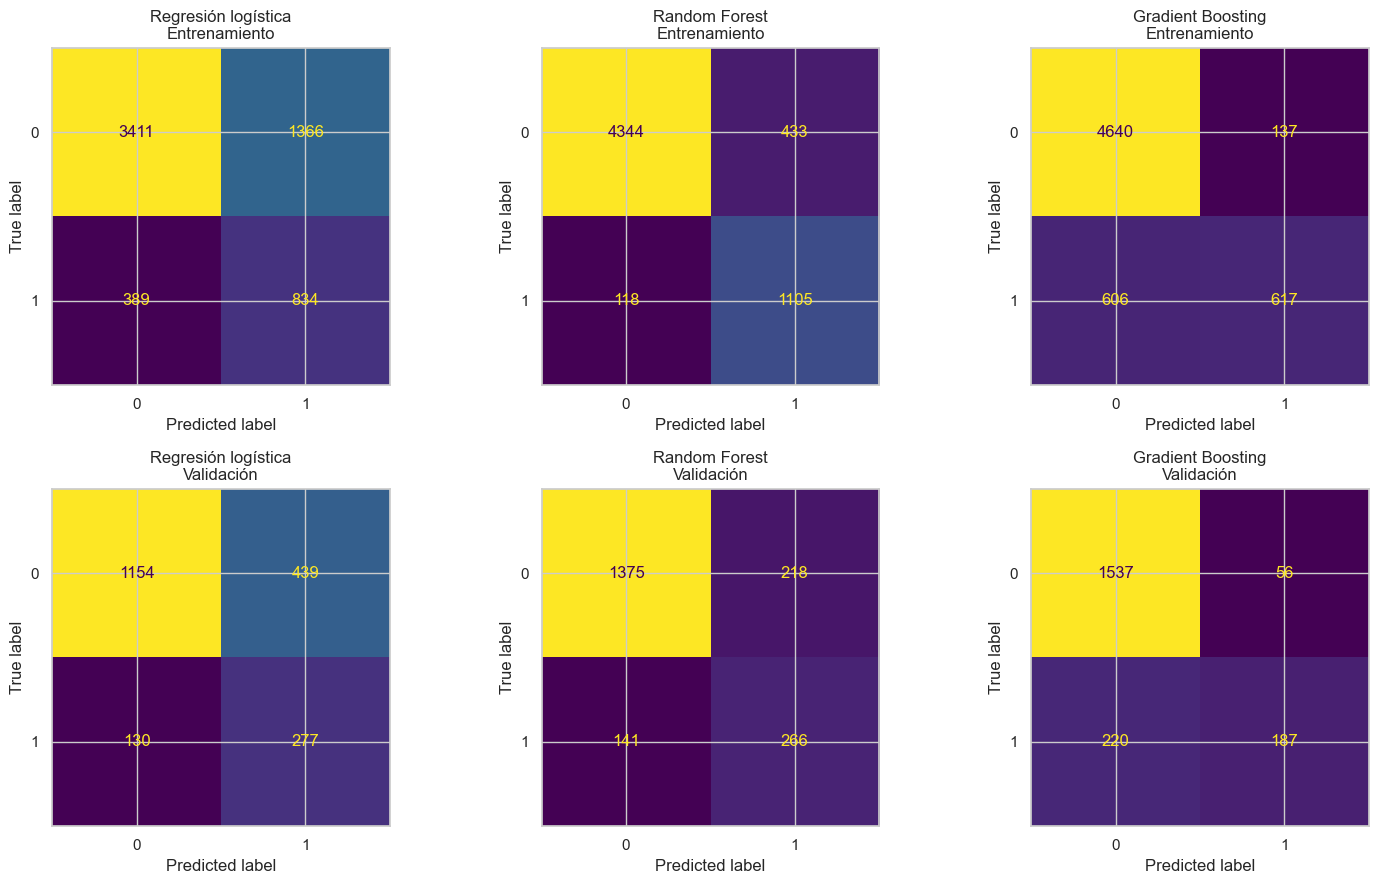

In [29]:
conjuntos_eval = {"Entrenamiento": (X_train_esc, y_train), "Validación": (X_val_esc, y_val)}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for fila, (titulo, (X, y)) in zip(axes, conjuntos_eval.items()):
    for ax, (nombre, modelo) in zip(fila, modelos.items()):
        ConfusionMatrixDisplay.from_predictions(y, modelo.predict(X), ax=ax, colorbar=False)
        ax.set_title(f"{nombre}\n{titulo}")
plt.tight_layout()
plt.show()

**Lectura de las matrices (validación, 407 clientes que se van).** La regresión logística detecta 277 (VP) y deja ir a 130 (FN), pero marca a 439 clientes que no se iban (FP). El Random Forest detecta 266, deja ir a 141 y tiene 218 falsas alarmas. El Gradient Boosting detecta 187, deja ir a 220 y solo tiene 56 falsas alarmas: es el que menos clientes marca y el que más abandonos pierde. En entrenamiento el Random Forest detecta 1.105 abandonos con 118 sin detectar, y en validación 266 con 141 sin detectar; esa caída del recall (0,904 a 0,654, en la tabla de 3.2) muestra el sobreajuste que ya mostraba la brecha de AUC.

### 3.2 Métricas

In [30]:
def metricas(modelo, X, y):
    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]
    vn, fp, fn, vp = confusion_matrix(y, y_pred).ravel()
    return {"exactitud": accuracy_score(y, y_pred), "precision": precision_score(y, y_pred),
            "recall": recall_score(y, y_pred), "f1": f1_score(y, y_pred),
            "auc": roc_auc_score(y, y_prob), "ap": average_precision_score(y, y_prob),
            "VP (abandonos detectados)": vp, "FP (falsas alarmas)": fp, "FN (abandonos no detectados)": fn}

tabla = pd.DataFrame({(nombre, titulo): metricas(modelo, X, y)
                      for nombre, modelo in modelos.items()
                      for titulo, (X, y) in conjuntos_eval.items()}).T
tabla.round(3)

exactitud  precision  recall     f1    auc  \
Regresión logística Entrenamiento      0.708      0.379   0.682  0.487  0.764   
                    Validación         0.716      0.387   0.681  0.493  0.762   
Random Forest       Entrenamiento      0.908      0.718   0.904  0.800  0.973   
                    Validación         0.820      0.550   0.654  0.597  0.840   
Gradient Boosting   Entrenamiento      0.876      0.818   0.504  0.624  0.895   
                    Validación         0.862      0.770   0.459  0.575  0.848   

                                      ap  VP (abandonos detectados)  \
Regresión logística Entrenamiento  0.456                      834.0   
                    Validación     0.441                      277.0   
Random Forest       Entrenamiento  0.921                     1105.0   
                    Validación     0.649                      266.0   
Gradient Boosting   Entrenamiento  0.765                      617.0   
                    Validación     0.677                      187.0   

                                   FP (falsas alarmas)  \
Regresión logística Entrenamiento               1366.0   
                    Validación                   439.0   
Random Forest       Entrenamiento                433.0   
                    Validación                   218.0   
Gradient Boosting   Entrenamiento                137.0   
                    Validación                    56.0   

                                   FN (abandonos no detectados)  
Regresión logística Entrenamiento                         389.0  
                    Validación                            130.0  
Random Forest       Entrenamiento                         118.0  
                    Validación                            141.0  
Gradient Boosting   Entrenamiento                         606.0  
                    Validación                            220.0

In [31]:
# Razones concretas para el banco, con el umbral de 0,5 en validación
val = tabla.xs("Validación", level=1)
vp, fp, fn = val["VP (abandonos detectados)"], val["FP (falsas alarmas)"], val["FN (abandonos no detectados)"]
razones = pd.DataFrame({
    "clientes marcados": vp + fp,
    "de cada 100 marcados, se iban": 100 * vp / (vp + fp),
    "de cada 100 que se van, se detectan": 100 * vp / (vp + fn),
    "marcados por cada abandono detectado": (vp + fp) / vp,
})
print("Abandonos reales en validación:", int((vp + fn).iloc[0]), "de", len(y_val), "clientes")
razones.round(1)

Abandonos reales en validación: 407 de 2000 clientes


,clientes marcados,"de cada 100 marcados, se iban","de cada 100 que se van, se detectan",marcados por cada abandono detectado
Regresión logística,716.0,38.7,68.1,2.6
Random Forest,484.0,55.0,65.4,1.8
Gradient Boosting,243.0,77.0,45.9,1.3


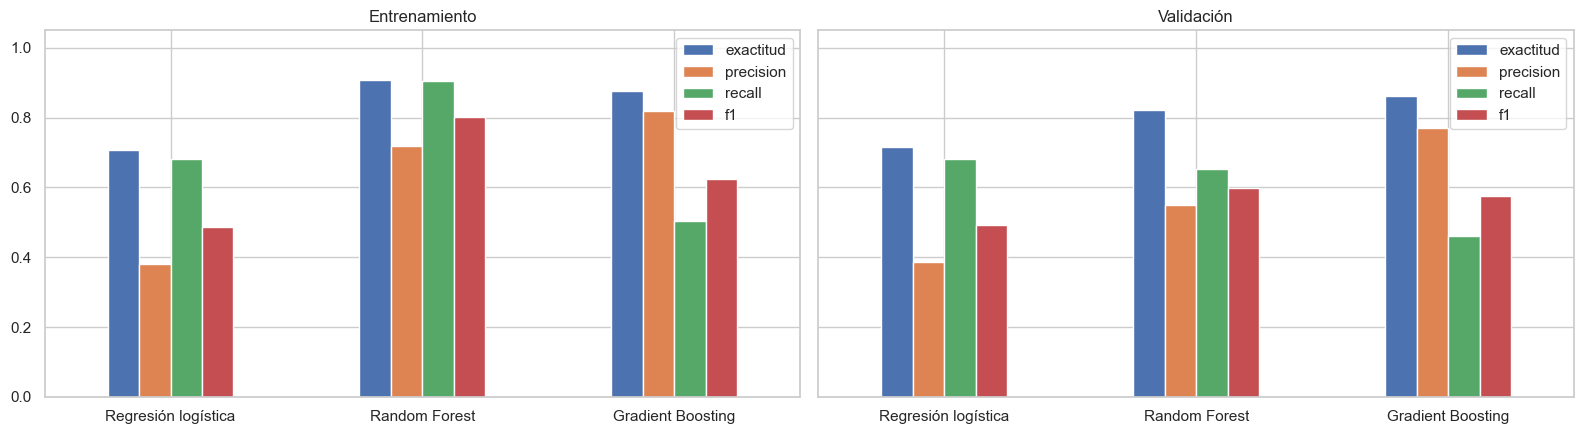

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, titulo in zip(axes, conjuntos_eval):
    tabla.xs(titulo, level=1)[["exactitud", "precision", "recall", "f1"]].astype(float).plot.bar(ax=ax, rot=0)
    ax.set_title(titulo)
    ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

**Qué significa cada métrica y qué vale para el banco** (validación, umbral 0,5, 407 clientes que se van de 2.000):

- **Precisión:** de los clientes que el modelo marca, cuántos sí se iban a ir. Cada falsa alarma es una oferta que se paga a alguien que se iba a quedar igual. De cada 100 clientes marcados, se iban 38,7 con la regresión logística, 55,0 con el Random Forest y 77,0 con el Gradient Boosting.
- **Recall:** de los clientes que de verdad se van, cuántos encuentra el modelo. Son los que se pueden intentar retener; el resto se pierde sin intento. De cada 100 que se van, el modelo encuentra 68,1 con la regresión logística, 65,4 con el Random Forest y 45,9 con el Gradient Boosting.
- **Clientes marcados por cada abandono detectado** (marcados dividido entre VP): cuántos clientes hay que contactar para llegar a uno que sí se iba. Es 2,6 con la regresión logística, 1,8 con el Random Forest y 1,3 con el Gradient Boosting. Como se paga por cada cliente contactado, esta razón está directamente asociada con el costo de la campaña.
- **F1:** el balance entre precisión y recall. Sirve para comparar, pero no incluye el costo de contactar ni lo que vale retener a un cliente.
- **AUC y AP:** miden qué tan bien ordena el modelo a los clientes por riesgo, sin fijar un umbral. Importan porque la campaña contacta en orden de riesgo y decide después a cuántos llegar. El AP pesa más el tope de la lista.
- **Exactitud:** sirve poco. Un modelo que siempre dice "no abandona" tiene 79,6 % (sección 1). La regresión logística, con 0,716 en validación, queda por debajo de esa línea base; el Random Forest (0,820) y el Gradient Boosting (0,862) la superan por poco.

El valor en dinero de estas razones (ingreso retenido menos costo de contacto) se calcula en la sección 5.

**Lectura del gráfico de barras.** En validación, el Gradient Boosting tiene la barra de precisión más alta (0,770) y la de recall más baja (0,459); la regresión logística tiene la precisión más baja (0,387) con un recall de 0,681; el Random Forest queda en medio en precisión (0,550) y tiene el mejor F1 (0,597, contra 0,575 del Gradient Boosting y 0,493 de la regresión logística). En entrenamiento el Random Forest sube a precisión 0,718, recall 0,904 y F1 0,800, frente a 0,550, 0,654 y 0,597 en validación; el Gradient Boosting pasa de F1 0,624 a 0,575. Con el umbral de 0,5 los tres modelos se comportan distinto, y eso parece asociarse con el umbral y los pesos de clase (la regresión logística y el Random Forest se entrenaron con `class_weight="balanced"` y el Gradient Boosting sin pesos), no solo con la calidad de cada modelo; en el Gradient Boosting, los pesos balanceados cambian el recall de 0,459 a 0,715 (sección 2.2). Por eso se comparan también con AUC y AP.

### 3.3 Curvas de precisión-recall y ROC (validación)

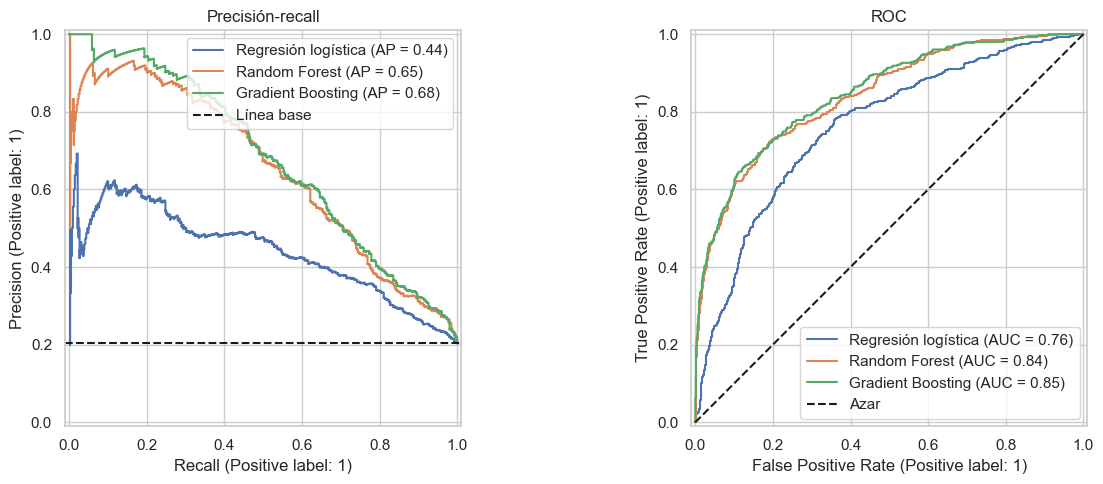

Tasa base de abandono en validación: 0.2035

Gradient Boosting menos Random Forest: AUC +0.008, AP +0.028
Gradient Boosting menos Random Forest, precisión en el 10 % de mayor riesgo: +0.020


,AUC,AP,precisión en el 10% de mayor riesgo (200 clientes),lift 10%,precisión en el 20% de mayor riesgo (400 clientes),lift 20%,F1 máximo en la rejilla,umbral de ese F1
Regresión logística,0.762,0.441,0.530,2.604,0.488,2.396,0.497,0.55
Random Forest,0.840,0.649,0.795,3.907,0.615,3.022,0.611,0.55
Gradient Boosting,0.848,0.677,0.815,4.005,0.610,2.998,0.610,0.25


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, modelo in modelos.items():
    PrecisionRecallDisplay.from_estimator(modelo, X_val_esc, y_val, ax=axes[0], name=nombre)
    RocCurveDisplay.from_estimator(modelo, X_val_esc, y_val, ax=axes[1], name=nombre)
axes[0].axhline(y_val.mean(), color="k", linestyle="--", label="Línea base")
axes[0].set_title("Precisión-recall")
axes[0].legend(loc="upper right")
axes[1].plot([0, 1], [0, 1], "k--", label="Azar")
axes[1].set_title("ROC")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

# Valores de las curvas y precisión al contactar a los clientes de mayor riesgo (validación)
tasa_base = y_val.mean()
print(f"Tasa base de abandono en validación: {tasa_base:.4f}")
rejilla = np.round(np.arange(0.05, 0.701, 0.05), 2)
filas_curvas = {}
for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_val_esc)[:, 1]
    orden = np.argsort(-prob, kind="stable")
    fila = {"AUC": roc_auc_score(y_val, prob), "AP": average_precision_score(y_val, prob)}
    for fraccion in (0.10, 0.20):
        n = int(round(fraccion * len(y_val)))
        precision_top = y_val.to_numpy()[orden[:n]].mean()
        fila[f"precisión en el {fraccion:.0%} de mayor riesgo ({n} clientes)"] = precision_top
        fila[f"lift {fraccion:.0%}"] = precision_top / tasa_base
    f1_rejilla = [f1_score(y_val, (prob >= u).astype(int)) for u in rejilla]
    fila["F1 máximo en la rejilla"] = max(f1_rejilla)
    fila["umbral de ese F1"] = rejilla[int(np.argmax(f1_rejilla))]
    filas_curvas[nombre] = fila
curvas = pd.DataFrame(filas_curvas).T
print(f"\nGradient Boosting menos Random Forest: AUC {curvas.loc['Gradient Boosting', 'AUC'] - curvas.loc['Random Forest', 'AUC']:+.3f}, AP {curvas.loc['Gradient Boosting', 'AP'] - curvas.loc['Random Forest', 'AP']:+.3f}")
col10 = [c for c in curvas.columns if c.startswith("precisión en el 10%")][0]
print(f"Gradient Boosting menos Random Forest, precisión en el 10 % de mayor riesgo: {curvas.loc['Gradient Boosting', col10] - curvas.loc['Random Forest', col10]:+.3f}")
curvas.round(3)

**Lectura de las curvas y del lift (validación, valores impresos arriba).** El AUC es 0,848 para el Gradient Boosting, 0,840 para el Random Forest y 0,762 para la regresión logística. El AP es 0,677, 0,649 y 0,441, frente a una línea base de 0,2035 (la tasa de abandono). En la curva ROC el Gradient Boosting y el Random Forest casi se superponen (0,008 de diferencia en AUC); en la de precisión-recall el Gradient Boosting queda por encima (0,028 más de AP), y ambos quedan muy por encima de la regresión logística.

El **lift** compara la precisión al contactar solo a los clientes de mayor riesgo con la tasa base. Con el Gradient Boosting, entre el 10 % de mayor riesgo (200 clientes) la precisión es 0,815, es decir 4,005 veces la tasa base de 0,2035; entre el 20 % (400 clientes) es 0,610, es decir 2,998 veces. En el 10 % el Gradient Boosting queda 0,020 por encima del Random Forest (0,815 contra 0,795); en el 20 % son equivalentes (0,610 contra 0,615). Si cada modelo toma su mejor umbral de la rejilla, el F1 máximo también es casi igual: 0,611 para el Random Forest (umbral 0,55) y 0,610 para el Gradient Boosting (umbral 0,25), contra 0,497 de la regresión logística. Es decir, la ventaja de los árboles sobre la regresión logística es clara, y la diferencia entre los dos árboles es pequeña.

### 3.4 Efecto del umbral (modelo elegido, validación)

El umbral de 0,5 no tiene por qué ser el mejor. Al bajarlo se contacta a más clientes y se detectan más abandonos, pero también aumentan las falsas alarmas. La tabla recorre umbrales de 0,05 a 0,70 cada 0,05 e incluye cuántos clientes se contactan por cada abandono detectado.

In [34]:
modelo_final = modelos[mejor]
y_prob_val = modelo_final.predict_proba(X_val_esc)[:, 1]
filas = []
for umbral in np.round(np.arange(0.05, 0.701, 0.05), 2):
    y_pred = (y_prob_val >= umbral).astype(int)
    vp_u = int(((y_pred == 1) & (y_val == 1)).sum())
    filas.append({"umbral": umbral, "precision": precision_score(y_val, y_pred), "recall": recall_score(y_val, y_pred),
                  "f1": f1_score(y_val, y_pred), "clientes_contactados": int(y_pred.sum()), "VP": vp_u,
                  "contactados_por_VP": y_pred.sum() / vp_u if vp_u else np.nan})
tabla_umbral = pd.DataFrame(filas).set_index("umbral")

# Umbral técnico de referencia: el de mayor F1 en validación (la prueba no interviene)
umbral_f1 = float(tabla_umbral["f1"].idxmax())
print(f"Umbral de mayor F1 en validación (umbral_f1): {umbral_f1} con F1 = {tabla_umbral.loc[umbral_f1, 'f1']:.3f}")
print(f"De 0,5 a {umbral_f1}: abandonos detectados {int(tabla_umbral.loc[umbral_f1, 'VP'] - tabla_umbral.loc[0.5, 'VP']):+d}, clientes contactados {int(tabla_umbral.loc[umbral_f1, 'clientes_contactados'] - tabla_umbral.loc[0.5, 'clientes_contactados']):+d}")
tabla_umbral.round(3)

Umbral de mayor F1 en validación (umbral_f1): 0.25 con F1 = 0.610
De 0,5 a 0.25: abandonos detectados +81, clientes contactados +228


,precision,recall,f1,clientes_contactados,VP,contactados_por_VP
umbral,,,,,,
0.05,0.276,0.966,0.429,1424,393,3.623
0.10,0.354,0.845,0.499,972,344,2.826
0.15,0.432,0.779,0.556,733,317,2.312
0.20,0.490,0.720,0.583,598,293,2.041
0.25,0.569,0.658,0.610,471,268,1.757
0.30,0.621,0.597,0.609,391,243,1.609
0.35,0.663,0.541,0.595,332,220,1.509
0.40,0.692,0.501,0.581,295,204,1.446
0.45,0.718,0.469,0.568,266,191,1.393


**Lectura de la tabla.** El mayor F1 en validación es 0,610 con el umbral de **0,25**, que queda guardado en `umbral_f1`; con 0,30 el F1 es 0,609, así que la curva es plana entre 0,25 y 0,30. Con 0,25 se contactan 471 clientes, se detectan 268 abandonos (recall 0,658), la precisión es 0,569 y se contacta a 1,757 clientes por cada abandono detectado. Con 0,5 se contactan 243, se detectan 187 (recall 0,459) y la razón es 1,299. Bajar de 0,5 a 0,25 agrega 81 abandonos detectados (268 contra 187) a cambio de contactar a 228 clientes más (471 contra 243). En los extremos, con 0,05 el recall es 0,966 pero se contactan 1.424 clientes (3,623 por abandono detectado), y con 0,70 la precisión es 0,894 pero el recall cae a 0,310 con 141 contactados.

`umbral_f1` es el **umbral técnico de referencia**, elegido solo con validación. El umbral de negocio se fija en la sección 5 según la ganancia, y puede ser distinto: depende de cuánto cuesta contactar y cuánto vale retener a un cliente, datos que el F1 no usa.

### 3.5 Evaluación en el conjunto de prueba

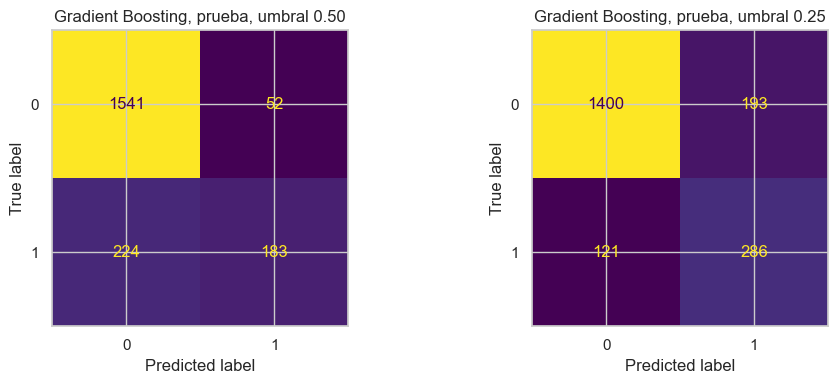

Exactitud de la línea base en prueba (siempre 0): 0.796
Abandonos reales en prueba: 407 de 2000 clientes
umbral_f1 (fijado en validación): 0.25
                    Validación, 0.50  Prueba, 0.50  Validación, 0.25  Prueba, 0.25
precisión                      0.770         0.779             0.569         0.597
recall                         0.459         0.450             0.658         0.703
F1                             0.575         0.570             0.610         0.646
contactados                  243.000       235.000           471.000       479.000
VP                           187.000       183.000           268.000       286.000
FP                            56.000        52.000           203.000       193.000
FN                           220.000       224.000           139.000       121.000
contactados por VP             1.299         1.284             1.757         1.675

AUC: validación 0.848, prueba 0.864, diferencia (validación - prueba) -0.016
AP: validación 0.677, prueba 0.

In [35]:
y_prob_test = modelo_final.predict_proba(X_test_esc)[:, 1]

def evaluar(y, prob, umbral):
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred).ravel()
    return {"precisión": precision_score(y, pred), "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "contactados": int(pred.sum()), "VP": vp, "FP": fp, "FN": fn, "contactados por VP": pred.sum() / vp}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, umbral in zip(axes, (0.5, umbral_f1)):
    ConfusionMatrixDisplay.from_predictions(y_test, (y_prob_test >= umbral).astype(int), ax=ax, colorbar=False)
    ax.set_title(f"{mejor}, prueba, umbral {umbral:.2f}")
plt.tight_layout()
plt.show()

print(f"Exactitud de la línea base en prueba (siempre 0): {accuracy_score(y_test, np.zeros(len(y_test), dtype=int)):.3f}")
print(f"Abandonos reales en prueba: {int(y_test.sum())} de {len(y_test)} clientes")
print(f"umbral_f1 (fijado en validación): {umbral_f1}")
comparacion = pd.DataFrame({
    "Validación, 0.50": evaluar(y_val, y_prob_val, 0.5), "Prueba, 0.50": evaluar(y_test, y_prob_test, 0.5),
    f"Validación, {umbral_f1:.2f}": evaluar(y_val, y_prob_val, umbral_f1),
    f"Prueba, {umbral_f1:.2f}": evaluar(y_test, y_prob_test, umbral_f1)})
print(comparacion.round(3).to_string())

auc_val, auc_test = roc_auc_score(y_val, y_prob_val), roc_auc_score(y_test, y_prob_test)
ap_val, ap_test = average_precision_score(y_val, y_prob_val), average_precision_score(y_test, y_prob_test)
print(f"\nAUC: validación {auc_val:.3f}, prueba {auc_test:.3f}, diferencia (validación - prueba) {auc_val - auc_test:+.3f}")
print(f"AP: validación {ap_val:.3f}, prueba {ap_test:.3f}, diferencia (validación - prueba) {ap_val - ap_test:+.3f}")

In [36]:
# Intervalo de confianza bootstrap del 95 % en prueba (1.000 remuestreos de los clientes, semilla fija)
rng = np.random.default_rng(42)
y_t = y_test.to_numpy()
aucs, aps = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_t), len(y_t))
    aucs.append(roc_auc_score(y_t[idx], y_prob_test[idx]))
    aps.append(average_precision_score(y_t[idx], y_prob_test[idx]))
print(f"AUC en prueba: {auc_test:.3f}, IC 95 % bootstrap [{np.percentile(aucs, 2.5):.3f}, {np.percentile(aucs, 97.5):.3f}]")
print(f"AP en prueba: {ap_test:.3f}, IC 95 % bootstrap [{np.percentile(aps, 2.5):.3f}, {np.percentile(aps, 97.5):.3f}]")
print(f"AUC de validación ({auc_val:.3f}) dentro del intervalo de prueba: {np.percentile(aucs, 2.5) <= auc_val <= np.percentile(aucs, 97.5)}")
print(f"Ancho del intervalo: AUC {np.percentile(aucs, 97.5) - np.percentile(aucs, 2.5):.3f}, AP {np.percentile(aps, 97.5) - np.percentile(aps, 2.5):.3f}")


AUC en prueba: 0.864, IC 95 % bootstrap [0.843, 0.882]
AP en prueba: 0.706, IC 95 % bootstrap [0.663, 0.745]
AUC de validación (0.848) dentro del intervalo de prueba: True
Ancho del intervalo: AUC 0.039, AP 0.082


**Lectura de la evaluación en prueba** (2.000 clientes, 407 que se van; el modelo final se evalúa una sola vez y nada se ajustó con este conjunto; `umbral_f1` = 0,25 viene de validación).

- **Ordenamiento:** el AUC es 0,864 en prueba y 0,848 en validación (diferencia validación menos prueba: -0,016, es decir, prueba es algo mayor); el AP es 0,706 contra 0,677 (diferencia -0,029). Los intervalos bootstrap del 95 % (1.000 remuestreos, semilla 42) son [0,843; 0,882] para el AUC y [0,663; 0,745] para el AP, y el AUC de validación (0,848) cae dentro del intervalo del AUC de prueba. No hay caída entre validación y prueba, así que el modelo se comporta de forma consistente con clientes que no vio; el ancho de los intervalos (0,039 de AUC y 0,082 de AP, impresos arriba) indica cuánto puede variar la métrica solo por la muestra.
- **Umbral 0,5:** precisión 0,779 (0,770 en validación), recall 0,450 (0,459) y F1 0,570 (0,575). Se contactan 235 clientes: 183 se iban (VP), 52 no (FP) y 224 se van sin ser detectados (FN).
- **Umbral 0,25:** precisión 0,597 (0,569 en validación), recall 0,703 (0,658) y F1 0,646 (0,610). Se contactan 479 clientes: 286 se iban, 193 no, y 121 se van sin ser detectados. Se contacta a 1,675 clientes por cada abandono detectado (1,757 en validación). El F1 sube de 0,570 a 0,646 al pasar de 0,5 a 0,25, igual que en validación, aunque el umbral se fijó sin mirar la prueba. Que en prueba el F1 salga mayor que en validación (0,646 contra 0,610) no se interpreta como una ventaja del umbral; el bootstrap solo se calculó para AUC y AP, no para el F1.
- **Línea base:** decir que nadie se va detecta 0 de los 407; el modelo detecta 183 con el umbral de 0,5 y 286 con el de 0,25.

In [37]:
# 1) Árboles frente a regresión logística (AUC de validación cruzada)
lr, rf, gb = (resumen_cv[n]["AUC CV"] for n in ("Regresión logística", "Random Forest", "Gradient Boosting"))
print(f"AUC CV: logística {lr:.3f}, Random Forest {rf:.3f}, Gradient Boosting {gb:.3f}")
print(f"Diferencia sobre la logística: Random Forest +{rf - lr:.3f}, Gradient Boosting +{gb - lr:.3f}")

# 2) Limitar la profundidad (mejor AUC de CV de la rejilla según max_depth)
cv_rf = pd.DataFrame(busqueda_rf.cv_results_)
cv_rf["max_depth"] = cv_rf["param_max_depth"].astype(str)
cv_gb = pd.DataFrame(busqueda_gb.cv_results_)
print("\nRandom Forest, mejor AUC CV por max_depth:")
print(cv_rf.groupby("max_depth")["mean_test_roc_auc"].max().round(3).to_string())
print("Gradient Boosting, mejor AUC CV por max_depth:")
print(cv_gb.groupby("param_max_depth")["mean_test_roc_auc"].max().round(3).to_string())

# 3) Pesos balanceados (celda de la sección 2) y umbral (tabla de 3.4)
print("\nPesos balanceados en el Gradient Boosting (sección 2):")
print(comparacion_pesos[["AUC CV", "AUC val", "prob. media val", "recall val (0,5)", "precisión val (0,5)"]].round(3).to_string())
print(f"\nUmbral: recall en validación {tabla_umbral.loc[0.5, 'recall']:.3f} con 0,5 y {tabla_umbral.loc[umbral_f1, 'recall']:.3f} con {umbral_f1}; "
      f"F1 {tabla_umbral.loc[0.5, 'f1']:.3f} y {tabla_umbral.loc[umbral_f1, 'f1']:.3f}")

# 4) Experimento: ¿ayudó convertir en nulos los valores fuera de rango? Mismo Gradient Boosting, misma partición por índice
crudo = pd.read_csv("churn.csv").drop_duplicates().reset_index(drop=True)
crudo["country"] = crudo["country"].str.strip().str.title()
crudo["gender"] = crudo["gender"].str.strip().replace({"M": "Male", "F": "Female"})
crudo["estimated_salary"] = crudo["estimated_salary"].clip(lower=0)
assert (crudo[objetivo] == df[objetivo]).all()
n_fuera = {c: int(((crudo[c] < rangos[c][0]) | (crudo[c] > rangos[c][1])).sum()) for c in ("credit_score", "age", "tenure")}
print("\nValores fuera de rango que se conservan en la versión sin limpiar (el salario negativo se lleva a 0 en ambas):", n_fuera)
mejor_rf = cv_rf.groupby("max_depth")["mean_test_roc_auc"].max()
mejor_gb_prof = cv_gb.groupby("param_max_depth")["mean_test_roc_auc"].max()
print(f"Diferencias de AUC de CV: Random Forest max_depth 10 menos sin límite {mejor_rf['10'] - mejor_rf['None']:+.3f}; "
      f"Gradient Boosting profundidad 3 menos 2 {mejor_gb_prof[3] - mejor_gb_prof[2]:+.3f} y 3 menos 4 {mejor_gb_prof[3] - mejor_gb_prof[4]:+.3f}")
print("Total de valores fuera de rango conservados en la versión sin limpiar:", sum(n_fuera.values()))
X_crudo = pd.get_dummies(crudo, columns=categoricas, drop_first=True, dtype=int)[columnas]
X_tr, X_va = X_crudo.loc[X_train.index], X_crudo.loc[X_val.index]
med_crudo = X_tr.median()
X_tr, X_va = X_tr.fillna(med_crudo), X_va.fillna(med_crudo)
resultados_limpieza = {}
for etiqueta, (Xa, Xb) in {"con limpieza (nulos en fuera de rango)": (X_train, X_val), "sin limpieza (valores originales)": (X_tr, X_va)}.items():
    m = GradientBoostingClassifier(random_state=42, **busqueda_gb.best_params_).fit(Xa, y_train)
    p = m.predict_proba(Xb)[:, 1]
    resultados_limpieza[etiqueta] = {"AUC val": roc_auc_score(y_val, p), "AP val": average_precision_score(y_val, p)}
pd.DataFrame(resultados_limpieza).T.round(4)

AUC CV: logística 0.761, Random Forest 0.865, Gradient Boosting 0.868
Diferencia sobre la logística: Random Forest +0.104, Gradient Boosting +0.106

Random Forest, mejor AUC CV por max_depth:
max_depth
10      0.865
5       0.855
None    0.863
Gradient Boosting, mejor AUC CV por max_depth:
param_max_depth
2    0.863
3    0.868
4    0.866

Pesos balanceados en el Gradient Boosting (sección 2):
                       AUC CV  AUC val  prob. media val  recall val (0,5)  precisión val (0,5)
sin pesos               0.868    0.848            0.196             0.459                0.770
con pesos balanceados   0.865    0.845            0.364             0.715                0.494

Umbral: recall en validación 0.459 con 0,5 y 0.658 con 0.25; F1 0.575 y 0.610

Valores fuera de rango que se conservan en la versión sin limpiar (el salario negativo se lleva a 0 en ambas): {'credit_score': 4, 'age': 6, 'tenure': 3}
Diferencias de AUC de CV: Random Forest max_depth 10 menos sin límite +0.002; Gradien

,AUC val,AP val
con limpieza (nulos en fuera de rango),0.8480,0.6768
sin limpieza (valores originales),0.8482,0.6778


### 3.6 Elección del modelo, qué ayudó y qué mejorar

**Elección: Gradient Boosting** (200 árboles, `learning_rate=0,05`, `max_depth=3`, sin pesos). Es un empate técnico en AUC con el Random Forest: 0,868 ± 0,007 contra 0,865 ± 0,010 en validación cruzada, y 0,848 contra 0,840 en validación. El desempate se hace con otras cifras: la brecha entre entrenamiento y validación es 0,047 en el Gradient Boosting (AUC 0,895 contra 0,848) y 0,133 en el Random Forest (0,973 contra 0,840); el AP de validación es 0,677 contra 0,649; y la precisión entre el 10 % de mayor riesgo es 0,815 contra 0,795. En prueba solo se evaluó el modelo final, así que la prueba no participó en la decisión.

**Lo que el Random Forest hace mejor, y por qué no decide.** Con el umbral de 0,5 el Random Forest tiene mejor F1 (0,597 contra 0,575) y mejor recall (0,654 contra 0,459). Esa diferencia se asocia con el umbral y con el entrenamiento con pesos balanceados: si cada modelo toma su mejor umbral de la rejilla, el F1 máximo es 0,611 (Random Forest) contra 0,610 (Gradient Boosting), y entre el 20 % de mayor riesgo la precisión es 0,615 contra 0,610. Es decir, en ordenamiento los dos son casi iguales, y el Gradient Boosting generaliza con menos brecha.

**Qué se asocia con las métricas** (las cifras salen de las secciones 1 a 3):
- **Modelos de árboles:** el AUC de validación cruzada es 0,865 (Random Forest) y 0,868 (Gradient Boosting) contra 0,761 de la regresión logística, es decir, 0,104 y 0,106 más. En la sección 1 el churn tiene una relación que una recta no capta: es 56,0 % entre 51 y 60 años y 24,7 % sobre 60, y 7,6 % con 2 productos contra 27,7 % con 1 y 82,7 % con 3.
- **Profundidad de los árboles:** en el Random Forest, el mejor AUC de CV con `max_depth=10` es 0,865, contra 0,863 sin límite y 0,855 con 5. La diferencia entre 10 y sin límite (0,002) es menor que la desviación entre folds (0,010), así que no se puede afirmar que limitar la profundidad mejore el AUC; tampoco se midió la brecha del Random Forest sin límite. En el Gradient Boosting, la profundidad 3 (0,868) supera a la 2 (0,863) y a la 4 (0,866), con diferencias de 0,005 y 0,002 que también son menores que la desviación entre folds (0,007).
- **Pesos balanceados:** casi no cambian el ordenamiento (AUC de CV 0,865 con pesos contra 0,868 sin ellos; AUC de validación 0,845 contra 0,848), pero mueven el punto de corte: con umbral 0,5 el recall pasa de 0,459 a 0,715 y la precisión de 0,770 a 0,494, y la probabilidad media de 0,196 a 0,364 (la tasa real es 0,2035). Por eso el Gradient Boosting sin pesos es conservador con 0,5 y por eso se prefiere mover el umbral.
- **Umbral:** en validación, pasar de 0,5 a 0,25 sube el recall de 0,459 a 0,658 y el F1 de 0,575 a 0,610; en prueba, el F1 sube de 0,570 a 0,646. Mueve el recall en una magnitud comparable a la de los pesos balanceados (0,658 contra 0,715 en validación) sin reentrenar el modelo.
- **Limpieza de valores fuera de rango:** se probó entrenar el mismo Gradient Boosting con los valores originales (13 valores fuera de rango en total: 4 en credit_score, 6 en age y 3 en tenure, sobre 10.000 registros) y con la misma partición. El AUC de validación es 0,8480 con limpieza y 0,8482 sin ella, y el AP es 0,6768 y 0,6778. La limpieza no cambia la métrica (la diferencia es mucho menor que la desviación entre folds de 0,007); se mantiene porque esos valores no son posibles (por ejemplo, edades de -1 y 210), no porque mejore el modelo. Es un solo ajuste con hiperparámetros fijos.

**Valor para el banco.** En prueba, con el umbral técnico de 0,25, el modelo contacta a 479 clientes y llega a 286 de los 407 que se van (recall 0,703), con 1,675 clientes contactados por cada abandono detectado. Entre el 10 % de mayor riesgo, la precisión es 4,005 veces la tasa base (validación). La sección 5 convierte estas razones en ganancia.

**Oportunidades de mejora** (propuestas, no se midieron aquí):
- **Calibración:** la probabilidad media del Gradient Boosting en validación (0,196) es cercana a la tasa real (0,2035), pero no se evaluó la calibración por tramos. Conviene revisarla antes de usar las probabilidades para calcular dinero en la sección 5.
- **Variables nuevas:** razones como saldo sobre salario o un indicador de saldo 0 (en la sección 1, el churn es 13,9 % con saldo 0 y 24,1 % con saldo mayor que 0, y ningún cliente de Alemania tiene saldo 0).
- **Datos de comportamiento** (transacciones, quejas, uso de canales): los datos actuales describen el perfil del cliente, y esta información podría mejorar el ordenamiento.
- **Más clientes con 3 y 4 productos:** hay solo 266 y 60 (sección 1), así que las estimaciones para estos grupos son menos estables.
- **Regularización del Gradient Boosting** (`subsample`), que no se probó en la sección 2.
- **Comparar los dos árboles con un bootstrap pareado de la diferencia de AUC**, para medir si la ventaja del Gradient Boosting es distinta de cero; aquí el empate se resolvió con brecha y AP.

## 4. Interpretación del modelo

## 5. Valor para el negocio

Datos del enunciado: banco de 20.000 clientes, la campaña retiene al 30% de los que se iban a ir, se paga por cada cliente contactado, ingreso anual por cliente entre $500.000 y $900.000 y deserción de referencia de 15%.

## 6. Conclusiones y recomendación

## 7. Uso de IA